# Exploratory Data Analysis: Wine Quality Dataset

## Introduction

This notebook presents an exploratory data analysis of the Wine Quality dataset.

The main objectives of this analysis are to understand the structure and characteristics of the dataset, identify potential data quality issues, explore the distribution of the variables and investigate relationships between the physicochemical properties of wine and its quality.

The analysis is conducted using NumPy, Pandas, Matplotlib and Seaborn.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Dataset Loading

First, the dataset is loaded into a Pandas DataFrame for further analysis.


In [2]:
df = pd.read_csv("13-WineQT.csv") # Load the dataset

In [3]:
df.head() # Display the first five rows

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## 2. Initial Data Inspection

The structure, dimensions, data types and basic statistical properties of the dataset are examined.

In [11]:
# Check the dataset dimensions
df.shape

(1143, 13)

In [12]:
# Check columns, data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [13]:
# Generate descriptive statistics
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


## 3. Data Quality Check

The dataset is checked for missing values and duplicate rows to identify potential data quality issues.

In [14]:
# Check for missing values
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [15]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

## 4. Exploratory Data Analysis

The distributions of the variables and the relationships between them are explored using statistical visualizations.

### 4.1 Distribution of Wine Quality

The distribution of wine quality scores is examined to understand the frequency of each quality level in the dataset.

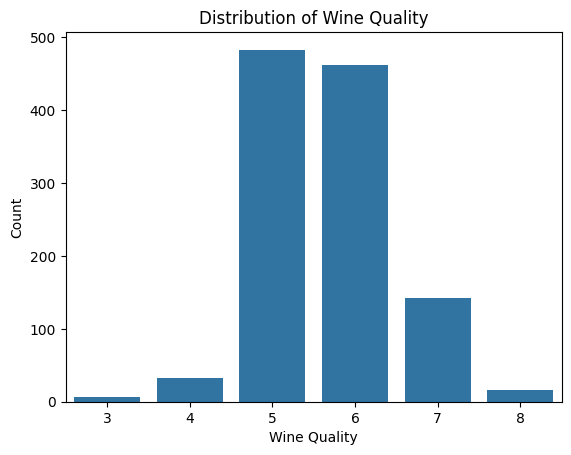

In [9]:
# Explore the distribution of wine quality
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Count")
plt.show()

### 4.2 Distribution of Numerical Variables

The distributions of the numerical variables are examined to understand their ranges, central tendencies, and variability.

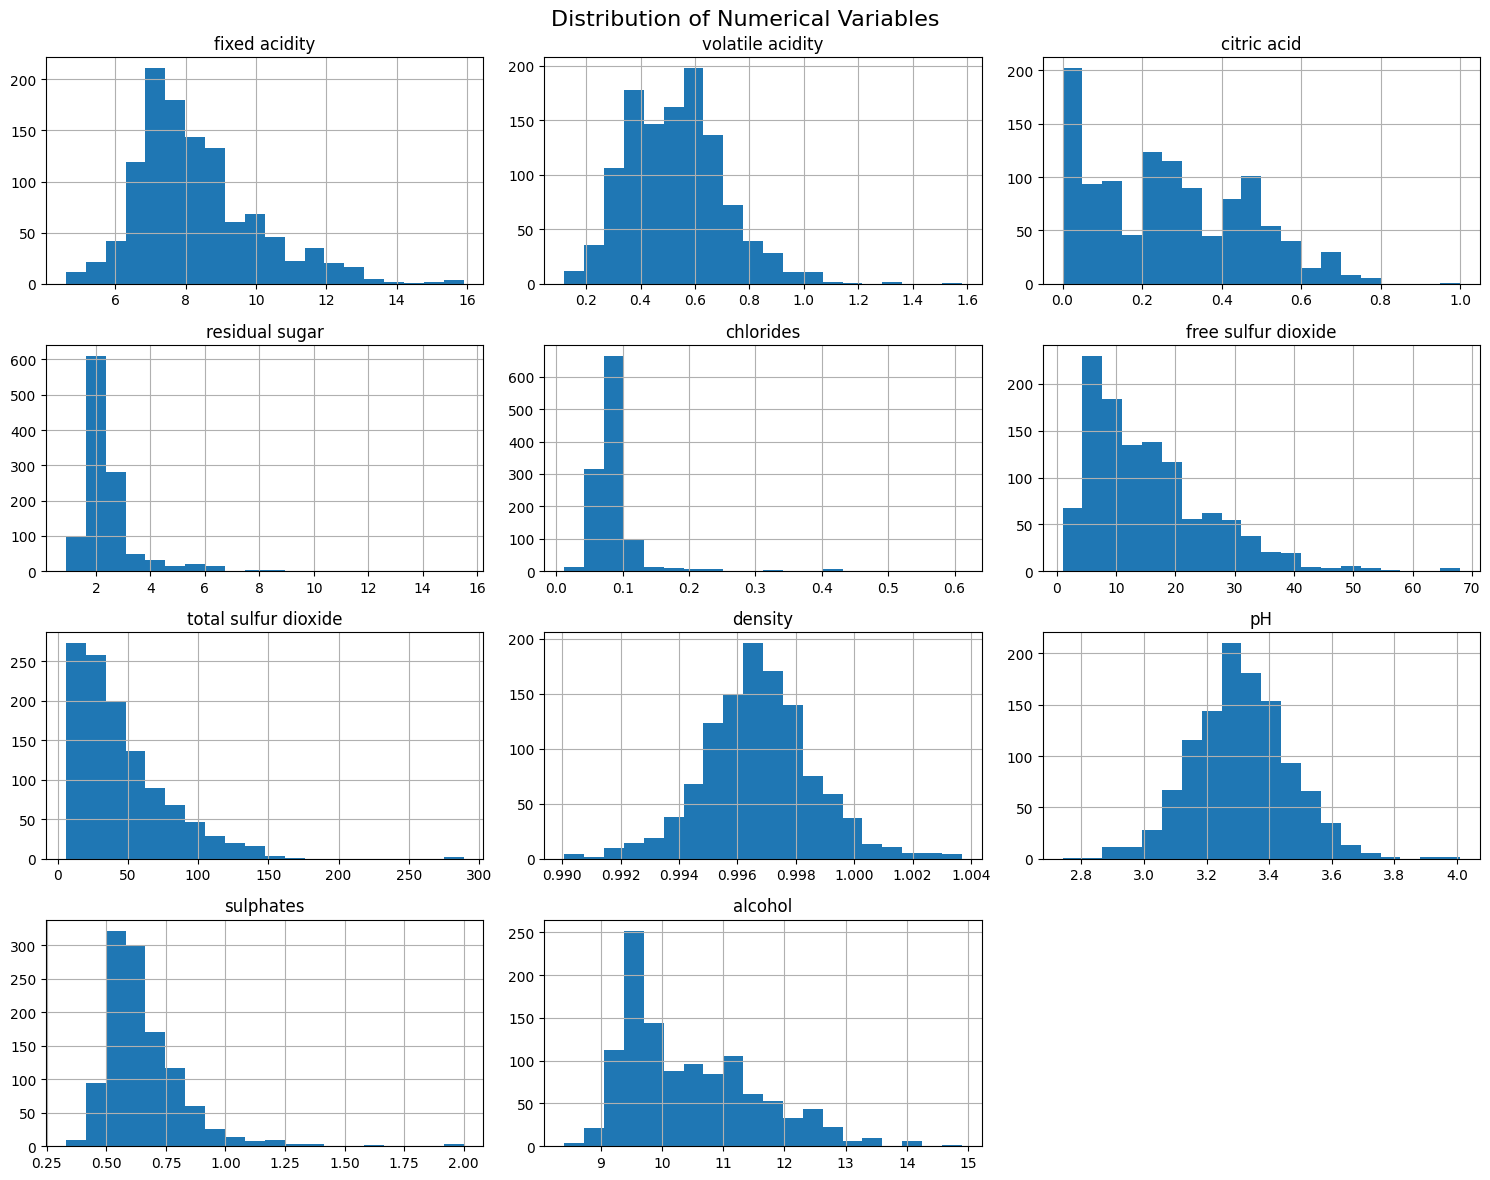

In [16]:
# Plot distributions of numerical variables
numerical_features = df.drop(columns=["quality", "Id"])

numerical_features.hist(figsize=(15, 12), bins=20)
plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

### 4.3 Correlation Analysis

The correlations between numerical variables are examined to identify potential relationships and patterns in the dataset.

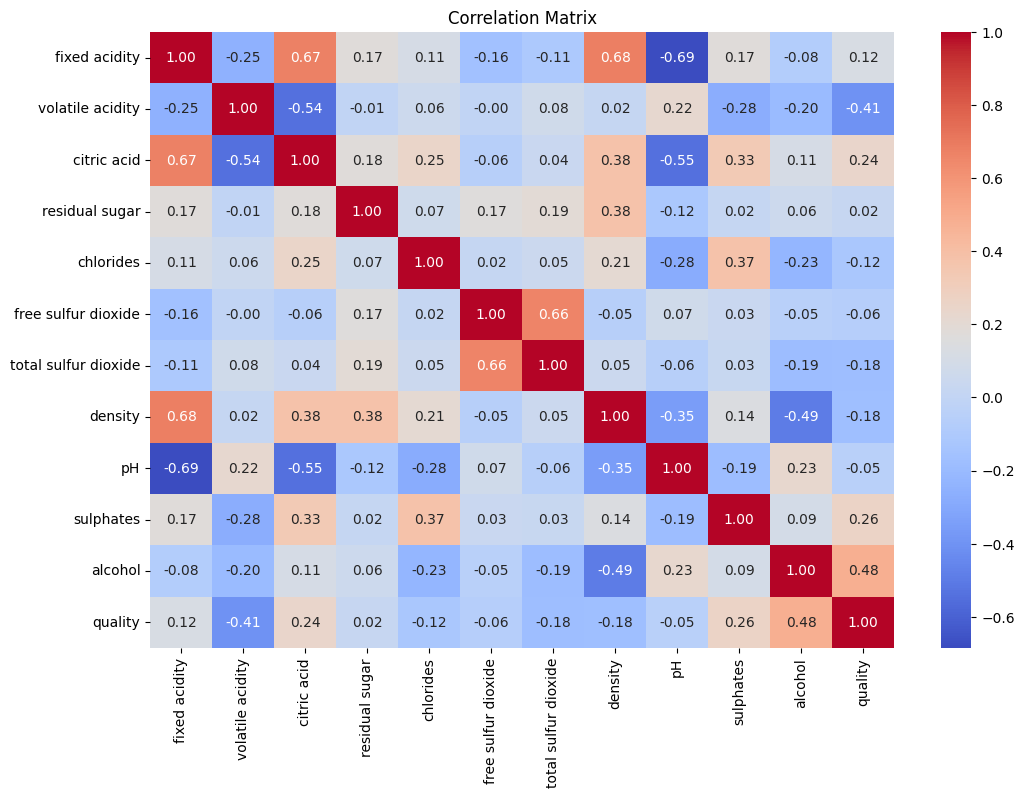

In [17]:
# Calculate and visualize the correlation matrix
correlation_matrix = df.drop(columns=["Id"]).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### 4.4 Outlier Analysis

Boxplots are used to identify potential outliers and examine the spread of the numerical variables.

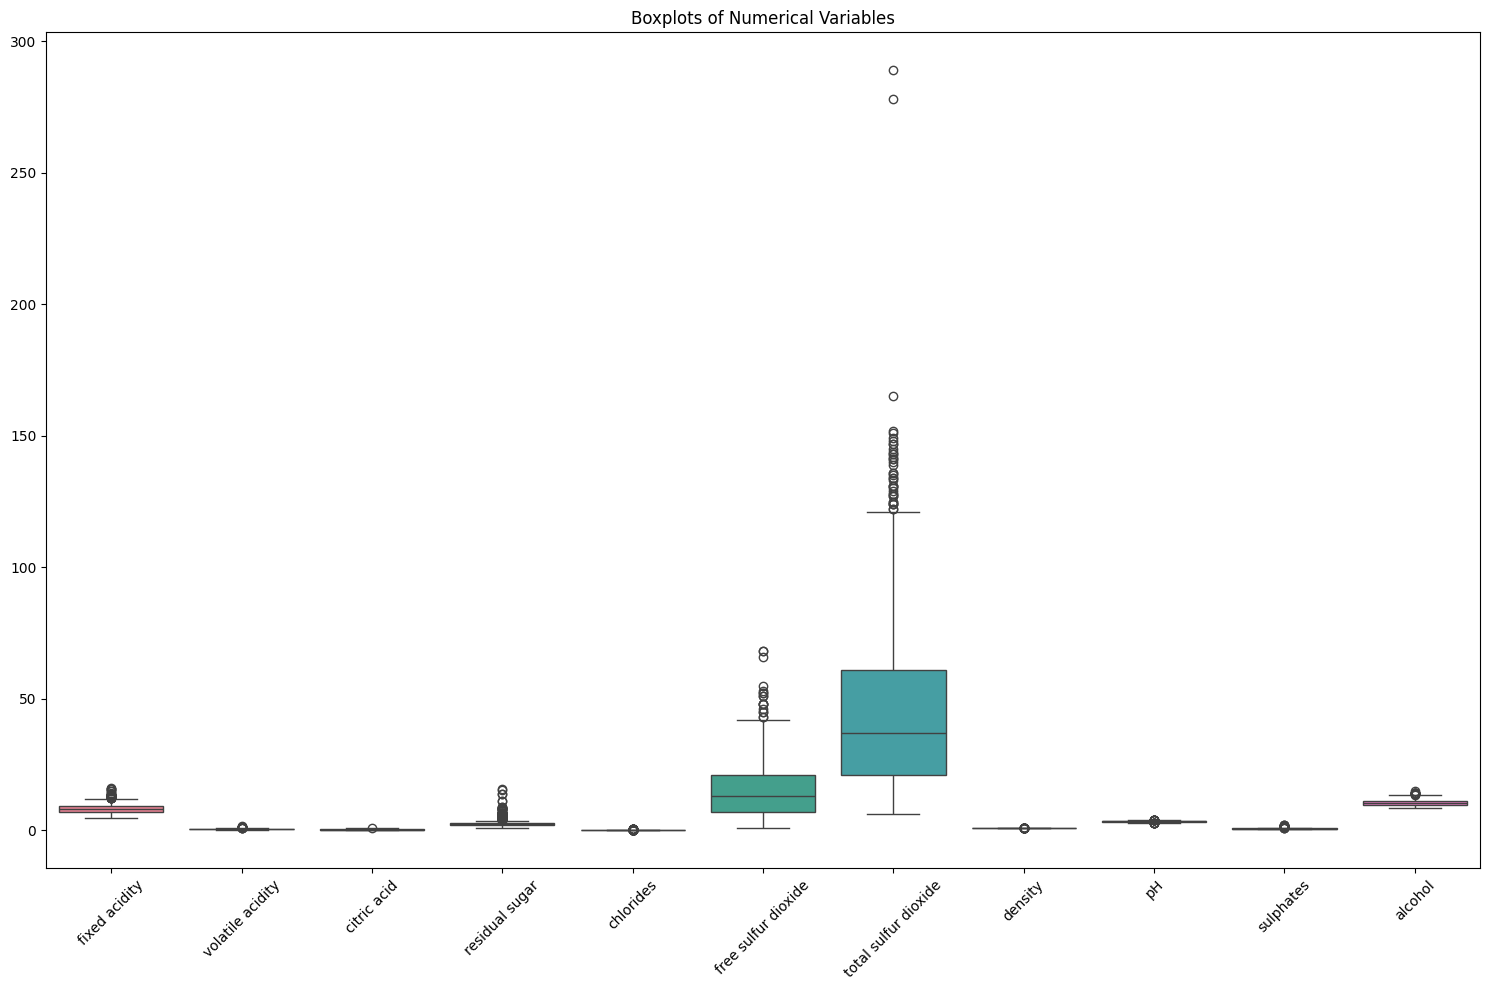

In [18]:
# Plot boxplots for numerical variables
plt.figure(figsize=(15, 10))

sns.boxplot(data=df.drop(columns=["quality", "Id"]))

plt.title("Boxplots of Numerical Variables")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.5 Relationship Between Wine Quality and Key Variables

The relationships between wine quality and selected physicochemical variables are explored using scatter plots.

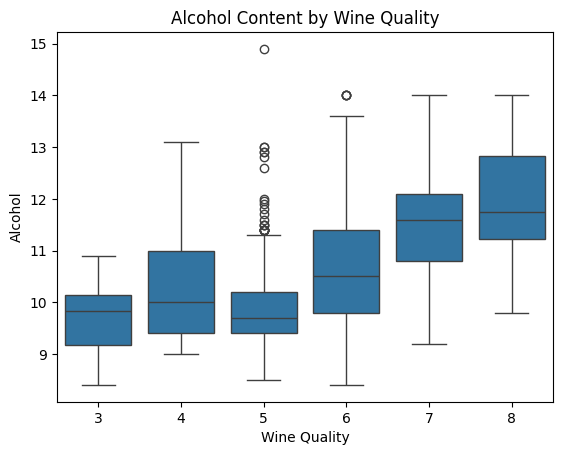

In [19]:
# Explore the relationship between alcohol and wine quality
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol Content by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol")
plt.show()

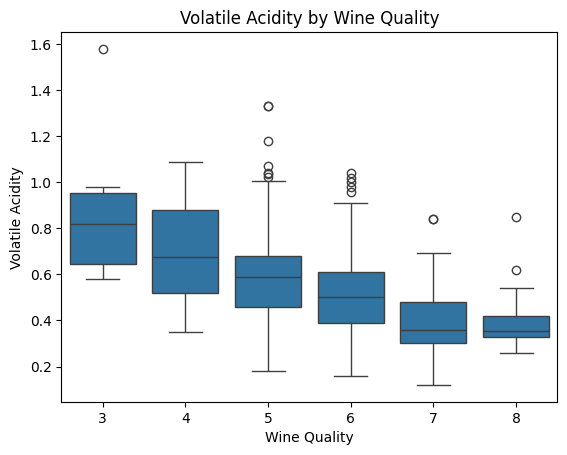

In [20]:
# Explore the relationship between volatile acidity and wine quality
sns.boxplot(data=df, x="quality", y="volatile acidity")
plt.title("Volatile Acidity by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Volatile Acidity")
plt.show()

### 4.6 Feature Overview

The main physicochemical features in the dataset are examined to understand what each variable represents and its role in wine quality analysis.

| Feature | Description |
|---|---|
| `fixed acidity` | Non-volatile acids that contribute to the overall acidity of wine. |
| `volatile acidity` | Volatile acids in wine, mainly associated with acetic acid. |
| `citric acid` | Citric acid content, which can contribute to freshness and flavor. |
| `residual sugar` | Amount of sugar remaining after fermentation. |
| `chlorides` | Chloride content of the wine, mainly related to salt concentration. |
| `free sulfur dioxide` | Free form of sulfur dioxide used to help preserve wine. |
| `total sulfur dioxide` | Total amount of free and bound sulfur dioxide. |
| `density` | Density of the wine, related to its composition and alcohol/sugar content. |
| `pH` | Measure of the acidity level of the wine. |
| `sulphates` | Sulphate content, which can contribute to preservation and wine characteristics. |
| `alcohol` | Alcohol concentration of the wine. |
| `quality` | Wine quality score assigned to the wine. |
| `Id` | Identifier of each observation. |

**Target variable:** `quality`

**Features:** `fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, and `alcohol`.

**Identifier:** `Id`

### 4.7 Quality and Other Relevant Features

The relationships between wine quality and other relevant physicochemical features are further explored based on the correlation analysis.

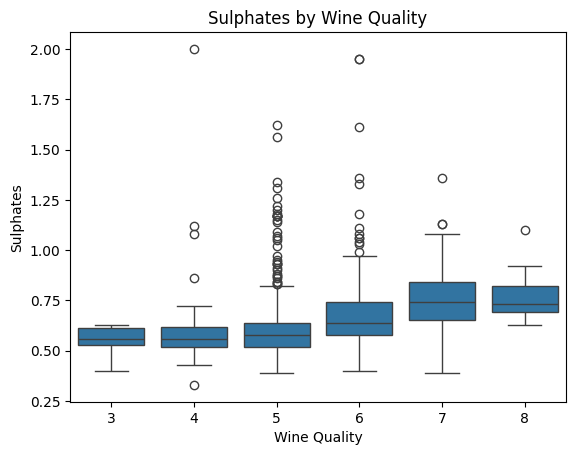

In [21]:
# Explore the relationship between sulphates and wine quality
sns.boxplot(data=df, x="quality", y="sulphates")
plt.title("Sulphates by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Sulphates")
plt.show()

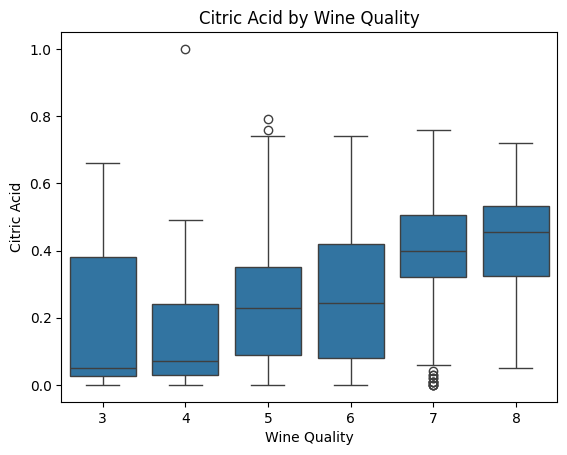

In [22]:
# Explore the relationship between citric acid and wine quality
sns.boxplot(data=df, x="quality", y="citric acid")
plt.title("Citric Acid by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Citric Acid")
plt.show()

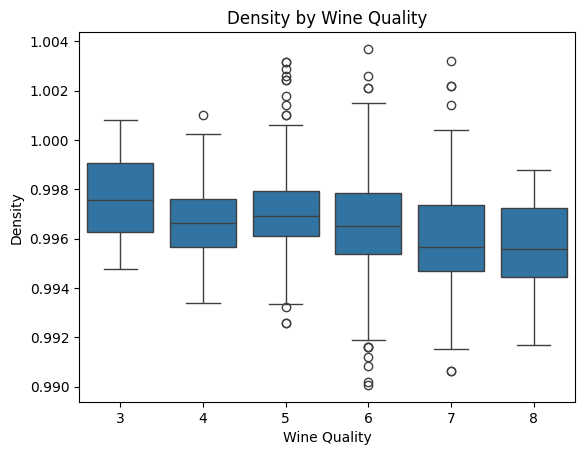

In [23]:
# Explore the relationship between density and wine quality
sns.boxplot(data=df, x="quality", y="density")
plt.title("Density by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Density")
plt.show()

## 5. Conclusion

This exploratory data analysis provided an overview of the Wine Quality dataset, including its structure, data quality, variable distributions, correlations and potential outliers.

The analysis also examined the relationships between wine quality and selected physicochemical properties.